# 04 — Baseline ML: Phúc

Mục tiêu: cho máy học từ 12 URL Features, rồi kiểm tra trên dữ liệu nó chưa được học.

Dummy là mốc đoán lớp đa số. Logistic Regression có hai cấu hình: thường và `class_weight="balanced"`; đây là cùng một thuật toán, chưa phải ba mô hình của báo cáo cuối kỳ.

Chọn cấu hình bằng F1 phishing trung bình trên 3 group folds; ngưỡng cố định 0,5. Official validation chỉ bổ sung, **test chưa được dự đoán/chấm điểm**.

## 0. Chọn đúng môi trường
Kernel: **PhishGuardVN (.venv)**. Chạy notebook 01 → 03 → 02 trước để có các CSV bàn giao. Các ô dưới dùng code chung, không viết lại parser hoặc tự chia ngẫu nhiên.

In [1]:
from pathlib import Path
import os
import sys
import tomllib

start = Path(os.environ.get("PHISHGUARD_ROOT", Path.cwd())).expanduser().resolve()
candidates = (start, *start.parents)
PROJECT_ROOT = next(
    (p for p in candidates if (p / "pyproject.toml").is_file()
     and (p / "src" / "phishguard_vn").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Chuyen working directory vao repo hoac dat PHISHGUARD_ROOT "
        "toi thu muc du an tren may ban."
    )
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from phishguard_vn.paths import get_data_dir, get_config_path
DATA_DIR = get_data_dir()
with get_config_path().open("rb") as handle:
    CONFIG = tomllib.load(handle)

print("Project:", PROJECT_ROOT)
print("Dataset:", DATA_DIR)
print("Config:", CONFIG["experiment"]["name"])


Project: D:\PhishGuardVN
Dataset: D:\PhishGuardVN\data
Config: week4_e1_core_lr


## 1. X là đầu vào, y là đáp án
`features`: id + 12 cột số do Hy tạo. `targets`: nhãn, split, tier và domain. `folds`: các ID train và fold_id do Hưng bàn giao. Các bảng nối bằng ID, không theo vị trí dòng.

In [2]:
from IPython.display import display, Image
from phishguard_vn.modeling import load_baseline_inputs, run_baseline, predict_url
from phishguard_vn.reporting import save_results
import pandas as pd
import joblib

features, targets, folds = load_baseline_inputs(PROJECT_ROOT)
print("X:", features.shape, "| Metadata:", targets.shape, "| Train folds:", len(folds))
display(features.head(3))
display(targets.groupby(["split", "label"]).size().unstack(fill_value=0))


X: (18995, 13) | Metadata: (18997, 5) | Train folds: 13078


,id,url_len,dom_len,is_ip,subdom_cnt,letter_cnt,digit_cnt,dot_cnt,dash_cnt,under_cnt,slash_cnt,entropy,path_len
0,75a477a7-aed5-5906-8d6c-e1fc739ef9fd,23.0,23.0,0.0,0.0,21.0,0.0,1.0,1.0,0.0,0.0,3.882045,0.0
1,939ebc8f-c54d-50f2-84e7-f02ed5a6aca5,17.0,17.0,0.0,0.0,15.0,0.0,1.0,1.0,0.0,0.0,3.381580,0.0
2,e3042cd5-fbb9-592c-a8af-0f9c61197b4d,16.0,16.0,0.0,0.0,11.0,4.0,1.0,0.0,0.0,0.0,3.452820,0.0


label,benign,phishing
split,,
test,3845,487
train,11004,2076
val,1561,24


## 2. Chạy baseline
Mỗi fold: học scaler và mô hình trên hai phần, chấm phần còn lại. Lặp lại cho đủ ba phần. Sau đó fit cấu hình đã chọn trên toàn bộ train để lưu artifact. Cả hai cấu hình LR dùng cùng dữ liệu và fold; không tuning threshold trong notebook này.

In [3]:
result = run_baseline(features, targets, folds, CONFIG)
print("Đã chạy. Test được đánh giá?", result["scope"]["test_evaluated"])
print("Cấu hình được chọn bằng CV:", result["selected_model"])


Đã chạy. Test được đánh giá? False
Cấu hình được chọn bằng CV: logistic_regression_balanced


## 3. Đọc kết quả CV
Precision: trong các cảnh báo phishing có bao nhiêu đúng? Recall: trong các phishing thật tìm ra bao nhiêu? F1 cân bằng hai đại lượng đó. PR-AUC ở đây dùng **average precision (AP)**. FPR là tỷ lệ benign bị cảnh báo nhầm. Không chỉ nhìn accuracy của Dummy.

In [4]:
display(result["cv_summary"])
display(result["cv_metrics"][["model", "fold_id", "n_benign", "n_phishing", "precision_phishing", "recall_phishing", "f1_phishing", "pr_auc", "fp", "fn"]])


,model,accuracy_mean,accuracy_std,precision_phishing_mean,precision_phishing_std,recall_phishing_mean,recall_phishing_std,f1_phishing_mean,f1_phishing_std,pr_auc_mean,pr_auc_std,false_positive_rate_mean,false_positive_rate_std
0,dummy_most_frequent,0.841413,0.000111,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.158587,0.000111,0.000000,0.000000
1,logistic_regression,0.873911,0.004759,0.729997,0.029375,0.326929,0.045412,0.449986,0.043073,0.594173,0.015811,0.022992,0.005331
2,logistic_regression_balanced,0.725877,0.014879,0.344914,0.012513,0.807131,0.008863,0.483148,0.010705,0.557744,0.015502,0.289440,0.019357


,model,fold_id,n_benign,n_phishing,precision_phishing,recall_phishing,f1_phishing,pr_auc,fp,fn
0,dummy_most_frequent,0,3668,691,0.000000,0.000000,0.000000,0.158523,0,691
1,dummy_most_frequent,1,3668,691,0.000000,0.000000,0.000000,0.158523,0,691
2,dummy_most_frequent,2,3668,692,0.000000,0.000000,0.000000,0.158716,0,692
3,logistic_regression,0,3668,691,0.744807,0.363242,0.488327,0.612305,86,440
4,logistic_regression,1,3668,691,0.696165,0.341534,0.458252,0.583263,103,455
5,logistic_regression,2,3668,692,0.749020,0.276012,0.403379,0.586950,64,501
6,logistic_regression_balanced,0,3668,691,0.344252,0.806078,0.482460,0.558739,1061,134
7,logistic_regression_balanced,1,3668,691,0.357745,0.798842,0.494181,0.541768,991,139
8,logistic_regression_balanced,2,3668,692,0.332744,0.816474,0.472803,0.572724,1133,127


## 4. Validation bổ sung
Validation core chỉ có 24 phishing, khác tỷ lệ lớp và nguồn của train. Dùng để mô tả khả năng chuyển sang split này, không đổi cấu hình đã chọn vì nhìn kết quả validation. Khi cần nghiên cứu threshold, làm thí nghiệm riêng bên trong train/CV.

In [5]:
display(result["validation_metrics"])


,model,evaluation_partition,threshold,n_rows,n_benign,n_phishing,accuracy,precision_phishing,recall_phishing,f1_phishing,pr_auc,pr_auc_definition,false_positive_rate,tn,fp,fn,tp
0,dummy_most_frequent,official_validation,0.5,1585,1561,24,0.984858,0.000000,0.000000,0.000000,0.015142,average_precision,0.000000,1561,0,24,0
1,logistic_regression,official_validation,0.5,1585,1561,24,0.970347,0.255319,0.500000,0.338028,0.293308,average_precision,0.022422,1526,35,12,12
2,logistic_regression_balanced,official_validation,0.5,1585,1561,24,0.591798,0.034380,0.958333,0.066378,0.274431,average_precision,0.413837,915,646,1,23


## 5. Lưu và xem biểu đồ
Model + metadata nằm trong models/; predictions lớn nằm trong data/interim/ và bị Git bỏ qua. Các bảng nhỏ và biểu đồ ở reports/. Đường PR dùng dự đoán OOF gộp; AP gộp có thể khác trung bình AP của từng fold.

Đã lưu: D:\PhishGuardVN\models\week4_lr_baseline.joblib


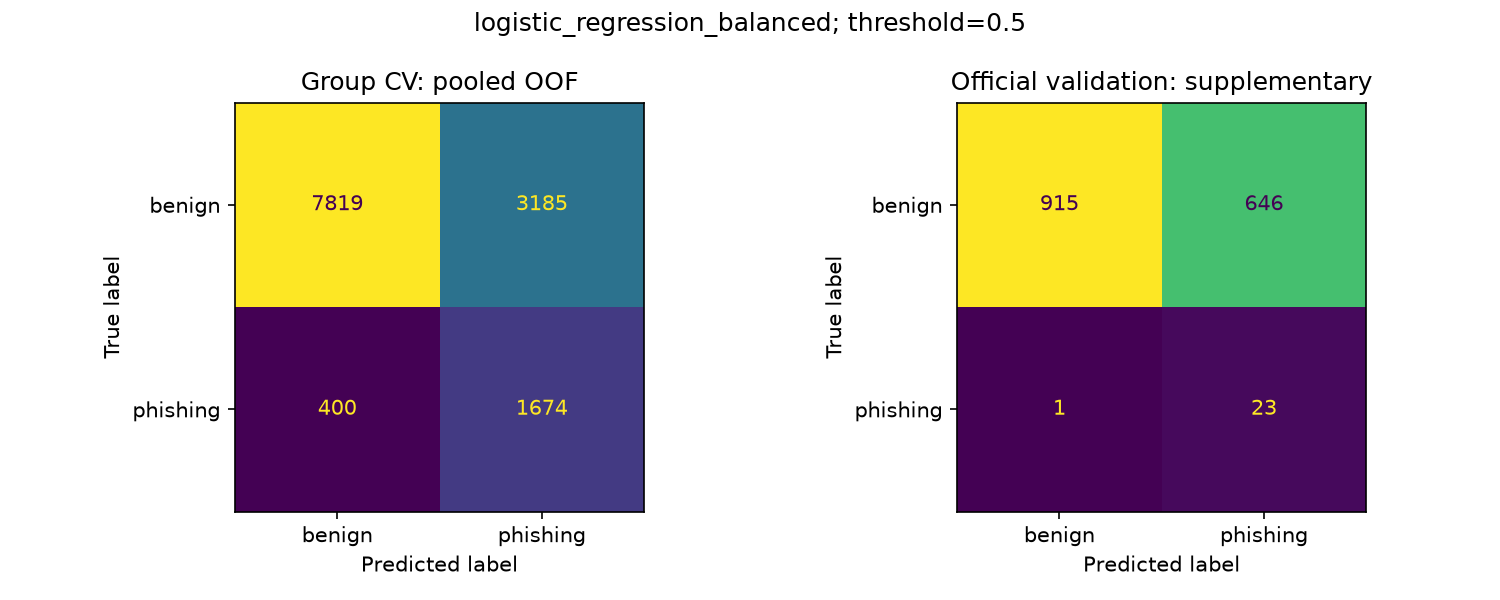

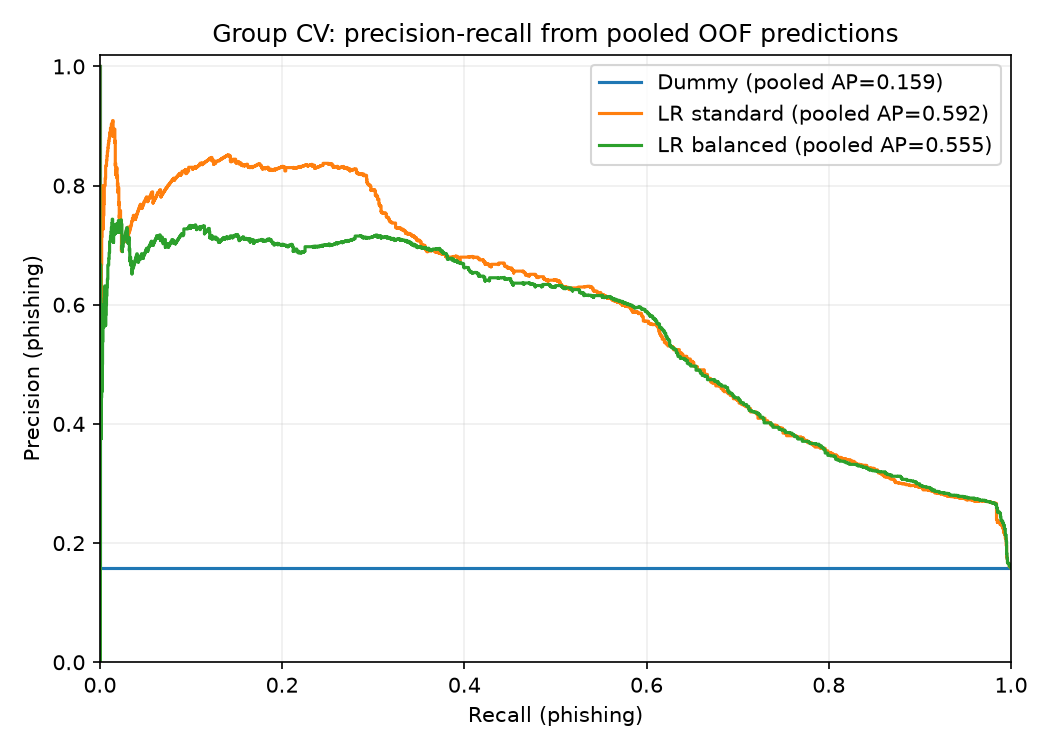

In [6]:
artifact_path = save_results(result, CONFIG, PROJECT_ROOT, get_config_path())
print("Đã lưu:", artifact_path)
display(Image(filename=str(PROJECT_ROOT / "reports/figures/04_confusion_matrices.png")))
display(Image(filename=str(PROJECT_ROOT / "reports/figures/04_precision_recall_cv.png")))


## 6. Phân tích FP/FN thực tế
Bảng lấy tối đa 5 FP và 5 FN, luân phiên fold 0 → 1 → 2 (trong mỗi fold sắp ID); mỗi loại có phân bổ 2/2/1 nếu đủ mẫu. Đây là mẫu đọc định tính, không đại diện thống kê toàn bộ lỗi. Các ô observation/hypothesis/next_check đã được phân tích từ URL, feature và nhãn gốc; xem thêm [báo cáo phân tích](../reports/week4_error_analysis.md).

URL chỉ được đối chiếu dưới dạng chuỗi, không truy cập website hay xác nhận website hiện tại. Không đổi nhãn vì mô hình đoán khác. Ghi chú tồn tại qua các lần chạy; 04_error_notes.csv lưu ghi chú cũ. Metadata ghi HEAD lúc chạy cùng trạng thái source và hash thực tế, không coi HEAD là một commit code sạch nếu source còn sửa.

In [7]:
examples = pd.read_csv(PROJECT_ROOT / "reports/tables/04_error_examples.csv")
core = pd.read_csv(PROJECT_ROOT / "data/interim/core_gold_silver.csv", low_memory=False)
review_errors = examples.merge(core[["id", "url", "source", "tier"]], on="id", validate="one_to_one")
review_errors["url"] = review_errors["url"].str.replace(".", "[.]", regex=False)
display(review_errors[["id", "error_type", "score", "url", "source", "tier", "fold_id", "observation", "hypothesis", "next_check"]])


,id,error_type,score,url,source,tier,fold_id,observation,hypothesis,next_check
0,00599d96-dd2c-5155-b9e9-f8dc8a42cb87,false_negative,0.447829,hhecy[.]space,tinnhiemmang,gold,0,"Fold 0: hhecy[.]space; phishing, tinnhiemmang/...",Feature đếm ký tự bỏ mất danh tính tên miền và...,Đối chiếu nhóm cùng vector và nhãn/label_sourc...
1,028cb900-502b-5b14-9949-4a8f5ca54e48,false_negative,0.493350,freefiremembership[.]com,tinnhiemmang,silver,1,"Fold 1: freefiremembership[.]com; phishing, ti...","Gần ngưỡng 0.5, trong khi 12 feature đếm không...",Đọc nhãn và impersonated_org/label_source gốc ...
2,01e34709-db9f-52dd-b60c-a064312ff7f4,false_negative,0.480338,pinuian[.]top,tinnhiemmang,gold,2,"Fold 2: pinuian[.]top; phishing, tinnhiemmang/...",Hai TLD .top/.space khác nhau nhưng vector trù...,Kiểm chứng phép so sánh vector của hai ID và s...
3,00becf11-e28e-5de3-a0ca-c9da1a7481ec,false_negative,0.491257,pocinex[.]com,tinnhiemmang,gold,0,"Fold 0: pocinex[.]com; phishing, tinnhiemmang/...",URL đơn giản nằm sát dưới ngưỡng và bị trùng b...,Đối chiếu nhóm cùng vector trong train và meta...
4,0342c07a-0919-5fe4-8f18-f6190af568b9,false_negative,0.475845,thongtincongty[.]com,tinnhiemmang,gold,1,"Fold 1: thongtincongty[.]com; phishing, tinnhi...",Tên gồm từ dễ đọc nhưng các feature đếm không ...,Kiểm tra nguồn nhãn/label_source trong CSV gốc...
5,0016e4c2-9ad3-508d-b431-7f8b71490403,false_positive,0.979006,maheir-3v78[.]shop,tranco,silver,0,Fold 0: maheir-3v78[.]shop; nhãn benign từ tra...,Kiểu chữ-số-gạch nối có thể giống phishing tro...,Đọc riêng đóng góp z*coef của digit_cnt/dash_c...
6,002a002e-29cd-5fac-9417-e47f49d54bd8,false_positive,0.533237,hoasenholdings[.]vn,tranco_vn,silver,1,"Fold 1: hoasenholdings[.]vn; benign, tranco_vn...",URL trông đơn giản vẫn nằm hơi trên ngưỡng 0.5...,"Trong train/CV, so sánh benign/phishing có cùn..."
7,0042fede-24f6-5b1b-a529-75a0c37b294b,false_positive,0.921202,d[.]vjst[.]vn,tinnhiem_web,gold,2,"Fold 2: d[.]vjst[.]vn; benign, tinnhiem_web/go...",Fold-2 LR có đóng góp dương lớn từ subdom_cnt ...,Kiểm tra phân bố FP trong benign có subdomain ...
8,001bc235-ae68-5a77-9033-f89e5f3a1a3d,false_positive,0.563085,vistarmedia[.]com,tranco,silver,0,"Fold 0: vistarmedia[.]com; benign, tranco/silv...",Có va chạm biểu diễn: URL khác nhãn có vector ...,Đối chiếu các ID cùng vector trong train và ng...
9,003ade32-5d37-50de-8921-dfd7aa6931a0,false_positive,0.519066,zhujuba[.]com,tranco,silver,1,"Fold 1: zhujuba[.]com; benign, tranco/silver; ...",Va chạm vector cùng ngưỡng cố định có thể giải...,Xem score và nhãn của nhóm cùng vector trong O...


## 7. Load mô hình để dự đoán URL mới
Dùng cùng parser/extractor và thứ tự cột như lúc train. Ví dụ example.com chỉ kiểm tra luồng kỹ thuật; chưa dùng làm bằng chứng chất lượng mô hình. Score là đầu ra mô hình chưa hiệu chuẩn, không phải xác suất an toàn đã được xác minh.

In [8]:
artifact = joblib.load(artifact_path)
example_prediction = predict_url(
    "https://example.com/a", artifact["pipeline"], artifact["feature_names"],
    artifact["decision_threshold"],
)
print(example_prediction)
try:
    predict_url("https://example.com:99999/", artifact["pipeline"], artifact["feature_names"])
except ValueError as exc:
    print("URL lỗi được báo rõ:", exc)


{'label': 'phishing', 'score': 0.6888355089797228, 'threshold': 0.5, 'score_definition': 'uncalibrated model predict_proba for phishing'}
URL lỗi được báo rõ: URL cannot be analyzed: invalid_port


## 8. Việc tiếp theo
- Đã phân tích 10 lỗi từ cả 3 fold; tiếp tục kiểm chứng các giả thuyết bằng train/CV trong thí nghiệm sau.
- Baseline hiện tại chưa phải mô hình cuối cùng; cần tiếp tục SVM/MLP và E2/E3 theo kế hoạch.
- Giữ nguyên test đến khi đã chốt quy trình lựa chọn.
- Xem báo cáo thực: reports/week4_baseline.md; chạy lại bằng `python scripts/train_baseline.py`.